# GCC1734 — IA | Companion 01
## Pré-treinamento autossupervisionado de um Transformer causal

**Objetivo:** observar todo o percurso **corpus → tokenizador BPE → tokens/IDs → embeddings → alvos autoregressivos → entropia cruzada → treinamento → geração**.

Neste notebook, criamos um Transformer causal **do zero**, com pesos aleatórios. Não usamos `from_pretrained()` para baixar um modelo de linguagem. O objetivo é ilustrar um procedimento de pré-treinamento em escala didática, não construir um LLM real.

**Continuidade:** o tokenizador e o checkpoint serão salvos e poderão ser usados nos notebooks de **SFT** e **alinhamento por preferências**.

> Pré-requisitos: Python 3.10+, `torch`, `transformers` (4.48–4.x), `tokenizers`, `accelerate`, `pandas` e `matplotlib`. Instale com `pip install -r requirements.txt` no terminal. Coloque o notebook e o corpus na mesma pasta.

### O que observar

1. IDs não contêm significado por si mesmos: apenas indexam o vocabulário.
2. O tokenizador **aprende unidades** a partir do corpus, mas **não aprende embeddings**.
3. O modelo aprende representações vetoriais e probabilidades **dos próprios tokens observados**, sem rótulos manuais.
4. A loss calculada pelo Transformer é a entropia cruzada com **deslocamento de uma posição**.
5. Perda menor em um corpus pequeno não implica competência linguística geral; examinar validação e textos novos é essencial.

In [1]:
from pathlib import Path
import math, random, inspect
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import transformers
from IPython.display import display

SEED = 1734
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

ARQUIVO = Path("corpora/corpus_sintetico.csv")
assert ARQUIVO.exists(), "Mantenha corpus_sintetico.csv na pasta corpora/."
print("PyTorch:", torch.__version__, "| Transformers:", transformers.__version__)
print("Aceleração:", "CUDA" if torch.cuda.is_available() else "CPU")

/Users/ebezerra/miniconda3/envs/gcc1734/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


PyTorch: 2.7.1 | Transformers: 4.53.1
Aceleração: CPU


## 1. Corpus sintético e separação treino/validação

O corpus contém frases curtas em quatro domínios (`animais`, `educacao`, `tecnologia`, `clima`). As estruturas são repetidas com combinações distintas de sujeitos, ações e complementos.

Os exemplos de validação não aparecem literalmente no treino, embora compartilhem palavras e padrões. **Cuidado:** isso avalia generalização combinatória limitada, não competência em português fora deste pequeno universo.

In [2]:
df = pd.read_csv(ARQUIVO)
display(df.head(12))
display(pd.crosstab(df["dominio"], df["split"], margins=True))
assert not set(df.query("split == 'treino'").texto) & set(df.query("split == 'validacao'").texto)
train_texts = df.loc[df.split == "treino", "texto"].tolist()
val_texts = df.loc[df.split == "validacao", "texto"].tolist()
print("Exemplo de treino:", train_texts[0])
print("Exemplo de validação:", val_texts[0])

,split,dominio,texto
0,treino,educacao,O monitor apresenta algoritmos no laboratório.
1,treino,animais,O urso brinca no quintal todos os dias.
2,validacao,clima,A nuvem chega ao amanhecer na montanha.
3,validacao,animais,O gato brinca na varanda.
4,treino,educacao,O estudante explica aprendizado de máquina na ...
5,treino,clima,A garoa aparece durante a noite na montanha.
6,treino,tecnologia,O algoritmo processa os exemplos com cuidado.
7,treino,clima,A tempestade chega pela manhã na cidade.
8,treino,educacao,O professor estuda programação na universidade.
9,treino,clima,O sol permanece durante a noite no vale.


split,treino,validacao,All
dominio,,,
animais,320,80,400
clima,320,80,400
educacao,320,80,400
tecnologia,320,80,400
All,1280,320,1600


Exemplo de treino: O monitor apresenta algoritmos no laboratório.
Exemplo de validação: A nuvem chega ao amanhecer na montanha.


## 2. Construir um tokenizador BPE

Usamos **Byte-level BPE** (*Byte Pair Encoding*). Inicialmente, o tokenizador opera com símbolos associados a bytes; durante seu treinamento, aprende fusões frequentes de unidades. Isso permite codificar palavras que não aparecem integralmente no corpus, sem depender de um token `<unk>` para caracteres comuns.

Os tokens especiais têm funções diferentes: `<bos>` marca o início da sequência, `<eos>` seu término e `<pad>` preenche exemplos de comprimentos diferentes em um lote.

**Distinção:** treinar o BPE escolhe um vocabulário e associa IDs; **treinar o Transformer** ajustará os embeddings e os demais pesos.

In [3]:
from tokenizers import Tokenizer, models, trainers, pre_tokenizers, decoders, processors
from transformers import PreTrainedTokenizerFast

SPECIAL = ["<pad>", "<bos>", "<eos>", "<unk>"]
backend = Tokenizer(models.BPE(unk_token="<unk>"))
backend.pre_tokenizer = pre_tokenizers.ByteLevel(add_prefix_space=False)
backend.decoder = decoders.ByteLevel()
bpe_trainer = trainers.BpeTrainer(
    vocab_size=384, min_frequency=2,
    initial_alphabet=pre_tokenizers.ByteLevel.alphabet(),
    special_tokens=SPECIAL,
)
backend.train_from_iterator(train_texts, trainer=bpe_trainer)
backend.post_processor = processors.TemplateProcessing(
    single="<bos> $A <eos>",
    special_tokens=[("<bos>", backend.token_to_id("<bos>")),
                    ("<eos>", backend.token_to_id("<eos>"))],
)
tokenizer = PreTrainedTokenizerFast(
    tokenizer_object=backend,
    bos_token="<bos>", eos_token="<eos>",
    pad_token="<pad>", unk_token="<unk>",
)
print("Tamanho do vocabulário:", len(tokenizer))
print("IDs especiais:", {t: tokenizer.convert_tokens_to_ids(t) for t in SPECIAL})
assert tokenizer.pad_token_id != tokenizer.eos_token_id




Tamanho do vocabulário: 384
IDs especiais: {'<pad>': 0, '<bos>': 1, '<eos>': 2, '<unk>': 3}


In [4]:
frases = [
    "O gato dorme no sofá.",
    "A professora ensina programação na escola.",
    "Os gatinhos brincam na varanda.",  # frase não vista integralmente
]
for frase in frases:
    ids = tokenizer(frase)["input_ids"]
    tabela = pd.DataFrame({
        "posição": range(len(ids)),
        "token BPE": tokenizer.convert_ids_to_tokens(ids),
        "ID": ids,
        "texto do token": [repr(tokenizer.decode([i], skip_special_tokens=False)) for i in ids],
    })
    print("\nTexto:", frase)
    display(tabela)
    print("Reconstrução:", tokenizer.decode(ids, skip_special_tokens=True))


Texto: O gato dorme no sofá.


,posição,token BPE,ID,texto do token
0,0,<bos>,1,'<bos>'
1,1,O,50,'O'
2,2,Ġ,224,' '
3,3,ga,314,'ga'
4,4,to,276,'to'
5,5,Ġd,264,' d'
6,6,or,272,'or'
7,7,me,287,'me'
8,8,Ġno,274,' no'
9,9,Ġs,345,' s'


Reconstrução: O gato dorme no sofá.

Texto: A professora ensina programação na escola.


,posição,token BPE,ID,texto do token
0,0,<bos>,1,'<bos>'
1,1,A,36,'A'
2,2,Ġpro,293,' pro'
3,3,fes,381,'fes'
4,4,s,86,'s'
5,5,ora,309,'ora'
6,6,Ġ,224,' '
7,7,en,308,'en'
8,8,s,86,'s'
9,9,i,76,'i'


Reconstrução: A professora ensina programação na escola.

Texto: Os gatinhos brincam na varanda.


,posição,token BPE,ID,texto do token
0,0,<bos>,1,'<bos>'
1,1,O,50,'O'
2,2,s,86,'s'
3,3,Ġ,224,' '
4,4,ga,314,'ga'
5,5,ti,294,'ti'
6,6,nh,286,'nh'
7,7,os,267,'os'
8,8,Ġ,224,' '
9,9,b,69,'b'


Reconstrução: Os gatinhos brincam na varanda.


**Investigação:** tokens byte-level podem apresentar símbolos como `Ġ` e `Ã` em sua forma interna. Esses símbolos são uma representação legível da codificação por bytes; o `decode` reconstrói o texto. Um ID próximo de outro não indica proximidade semântica.

## 3. De IDs a embeddings

A matriz de embeddings tem forma $E\in\mathbb{R}^{|V|\times d}$. O token ID seleciona uma linha. Os valores começam aleatórios e são ajustados durante o treinamento.

Vamos criar primeiro o modelo. **GPT-2** aqui indica o tipo de arquitetura decoder-only; não importamos pesos do GPT-2 comercial.

In [5]:
from transformers import GPT2Config, GPT2LMHeadModel

config = GPT2Config(
    vocab_size=len(tokenizer),
    n_positions=64,
    n_ctx=64,
    n_embd=64,
    n_layer=2,
    n_head=2,
    bos_token_id=tokenizer.bos_token_id,
    eos_token_id=tokenizer.eos_token_id,
    pad_token_id=tokenizer.pad_token_id,
    # Mantemos o dropout em zero para facilitar inspeções reproduzíveis
    resid_pdrop=0.0, embd_pdrop=0.0, attn_pdrop=0.0,
)
model = GPT2LMHeadModel(config)
print(f"Parâmetros totais: {model.num_parameters():,}")
print("Forma da matriz de embeddings:", tuple(model.get_input_embeddings().weight.shape))
frase = "O gato dorme no sofá."
ids = tokenizer(frase)["input_ids"]
with torch.no_grad():
    vetores = model.get_input_embeddings()(torch.tensor([ids]))
print("IDs:", ids)
print("Embeddings [lote, tokens, dimensões]:", tuple(vetores.shape))
print("Início do embedding do primeiro token:", vetores[0, 0, :8].tolist())

Parâmetros totais: 128,768
Forma da matriz de embeddings: (384, 64)
IDs: [1, 50, 224, 314, 276, 264, 272, 287, 274, 345, 82, 73, 342, 17, 2]
Embeddings [lote, tokens, dimensões]: (1, 15, 64)
Início do embedding do primeiro token: [0.01857043243944645, 0.013446145690977573, -0.009619059041142464, 0.036864008754491806, 0.01885201968252659, 0.02624562941491604, -0.0013740025460720062, 0.0020882473327219486]


## 4. Objetivos autoregressivos: `input_ids`, `labels` e deslocamento

Durante o treinamento causal, não criamos rótulos manualmente. Em geral, passamos `labels=input_ids` (exceto posições ignoradas). **Dentro de `GPT2LMHeadModel`**, as posições são deslocadas: o logit da posição $t$ prevê o ID da posição $t+1$.

Com `<bos>` e `<eos>`, a primeira previsão tem como contexto `<bos>` e alvo o primeiro token da frase. A última posição de entrada não possui próximo alvo na mesma sequência.

In [6]:
ids = tokenizer("O gato dorme no sofá.")["input_ids"]
print("IDs completos:", ids)
pares = []
for i in range(len(ids)-1):
    pares.append({
        "posição de entrada": i,
        "prefixo disponível": tokenizer.decode(ids[:i+1], skip_special_tokens=False),
        "próximo token (alvo)": tokenizer.convert_ids_to_tokens(ids[i+1]),
        "ID alvo": ids[i+1],
    })
display(pd.DataFrame(pares))

IDs completos: [1, 50, 224, 314, 276, 264, 272, 287, 274, 345, 82, 73, 342, 17, 2]


,posição de entrada,prefixo disponível,próximo token (alvo),ID alvo
0,0,<bos>,O,50
1,1,<bos>O,Ġ,224
2,2,<bos>O,ga,314
3,3,<bos>O ga,to,276
4,4,<bos>O gato,Ġd,264
5,5,<bos>O gato d,or,272
6,6,<bos>O gato dor,me,287
7,7,<bos>O gato dorme,Ġno,274
8,8,<bos>O gato dorme no,Ġs,345
9,9,<bos>O gato dorme no s,o,82


In [7]:
model.eval()
entrada = torch.tensor([ids])
with torch.no_grad():
    saida = model(input_ids=entrada, labels=entrada)
    logits = saida.logits
    perda_manual = torch.nn.functional.cross_entropy(
        logits[:, :-1, :].reshape(-1, len(tokenizer)),
        entrada[:, 1:].reshape(-1),
    )
print("Forma dos logits:", tuple(logits.shape))
print("Loss do modelo:", float(saida.loss))
print("Loss manual com deslocamento:", float(perda_manual))
assert torch.allclose(saida.loss, perda_manual, atol=1e-5)
print("As duas perdas coincidem.")

`loss_type=None` was set in the config but it is unrecognised.Using the default loss: `ForCausalLMLoss`.


Forma dos logits: (1, 15, 384)
Loss do modelo: 6.00421142578125
Loss manual com deslocamento: 6.00421142578125
As duas perdas coincidem.


## 5. Preparar lotes e treinar

O corpus foi tokenizado **apenas com exemplos de treino**. Os exemplos de validação são usados para observar o desempenho fora das frases literais vistas na otimização.

`DataCollatorForLanguageModeling(mlm=False)` preenche os lotes e cria `labels` iguais aos `input_ids`, trocando por `-100` os IDs de preenchimento. O modelo ignora posições com `-100` ao calcular a perda.

Abaixo, o número de etapas é limitado para tornar a atividade viável. Para explorar diferenças, ajuste `MAX_STEPS` e `LEARNING_RATE`. O tempo depende do hardware.

In [8]:
from torch.utils.data import Dataset
from transformers import DataCollatorForLanguageModeling, Trainer, TrainingArguments

MAX_LEN = 48
MAX_STEPS = 120  # reduzir para 40 em computadores lentos; aumentar para aprofundar
LEARNING_RATE = 5e-4
BATCH = 16

class TextDataset(Dataset):
    def __init__(self, textos, tokenizer):
        self.examples = tokenizer(textos, truncation=True, max_length=MAX_LEN)["input_ids"]
    def __len__(self):
        return len(self.examples)
    def __getitem__(self, index):
        return {"input_ids": self.examples[index]}

train_ds = TextDataset(train_texts, tokenizer)
val_ds = TextDataset(val_texts, tokenizer)
collator = DataCollatorForLanguageModeling(tokenizer=tokenizer, mlm=False)
mini_lote = collator([train_ds[0], train_ds[1], train_ds[2]])
print("Formas:", {k: tuple(v.shape) for k, v in mini_lote.items()})
print("Posições ignoradas (-100):", int((mini_lote["labels"] == -100).sum()))
assert (mini_lote["labels"] == -100).sum().item() >= 0

Formas: {'input_ids': (3, 29), 'attention_mask': (3, 29), 'labels': (3, 29)}
Posições ignoradas (-100): 8


### Inspecionar probabilidades antes do treinamento

O prompt deve terminar **antes** do token que queremos prever. A função abaixo calcula as próximas probabilidades a partir de `<bos>` e do texto digitado, sem inserir `<eos>` antes de fazer a previsão.

In [9]:
PROMPTS = ["O gato", "A professora", "O modelo", "A chuva"]

def proximo_token(model, tokenizer, prompt, n=6):
    model.eval()
    ids = [tokenizer.bos_token_id] + tokenizer(prompt, add_special_tokens=False)["input_ids"]
    inp = torch.tensor([ids], device=next(model.parameters()).device)
    with torch.no_grad():
        probs = model(input_ids=inp).logits[0, -1].softmax(-1)
    valores, indices = probs.topk(n)
    return pd.DataFrame({
        "token interno": tokenizer.convert_ids_to_tokens(indices.tolist()),
        "texto decodificado": [repr(tokenizer.decode([i])) for i in indices.tolist()],
        "probabilidade": valores.cpu().numpy(),
    })

previsoes_antes = {p: proximo_token(model, tokenizer, p, 8) for p in PROMPTS}
for p in PROMPTS:
    print("\nAntes do treinamento:", repr(p))
    display(previsoes_antes[p])


Antes do treinamento: 'O gato'


,token interno,texto decodificado,probabilidade
0,to,'to',0.006094
1,´,'�',0.004430
2,Ī,'�',0.003930
3,ĥ,'�',0.003907
4,Ġu,' u',0.003865
5,Ġex,' ex',0.003639
6,8,'8',0.003635
7,',"""'""",0.003630



Antes do treinamento: 'A professora'


,token interno,texto decodificado,probabilidade
0,ora,'ora',0.005021
1,Ġexp,' exp',0.003889
2,_,'_',0.003827
3,Đ,'\x10',0.003794
4,nte,'nte',0.003723
5,Ġdurante,' durante',0.003715
6,mos,'mos',0.003708
7,B,'B',0.003704



Antes do treinamento: 'O modelo'


,token interno,texto decodificado,probabilidade
0,o,'o',0.006161
1,ï,'�',0.003926
2,Ĉ,'\x08',0.003868
3,Z,'Z',0.003867
4,ã,'�',0.003732
5,Ãł,'à',0.003699
6,to,'to',0.003693
7,Ľ,'�',0.003669



Antes do treinamento: 'A chuva'


,token interno,texto decodificado,probabilidade
0,va,'va',0.004924
1,Ã§,'ç',0.004075
2,3,'3',0.003661
3,Ġpe,' pe',0.003619
4,Ń,'�',0.003614
5,8,'8',0.003551
6,Ý,'�',0.003512
7,I,'I',0.003510


**Geração antes do treinamento.** Guardamos as continuações gulosas para compará-las com as geradas após atualizar os parâmetros. Os resultados dependem da inicialização aleatória.

In [10]:
def gerar(model, tokenizer, prompt, amostrar=False):
    model.eval()
    ids = [tokenizer.bos_token_id] + tokenizer(prompt, add_special_tokens=False)["input_ids"]
    inputs = torch.tensor([ids], device=next(model.parameters()).device)
    options = dict(max_new_tokens=16, do_sample=amostrar,
                   eos_token_id=tokenizer.eos_token_id,
                   pad_token_id=tokenizer.pad_token_id)
    if amostrar:
        options.update(temperature=0.8, top_k=20)
    with torch.no_grad():
        out = model.generate(input_ids=inputs, **options)
    return tokenizer.decode(out[0], skip_special_tokens=True)

geracoes_antes = {p: gerar(model, tokenizer, p, amostrar=False) for p in PROMPTS}
for prompt in PROMPTS:
    print("\nPrompt:", repr(prompt))
    print("Antes (gulosa):", geracoes_antes[prompt])


Prompt: 'O gato'
Antes (gulosa): O gatototototototototototototototototo

Prompt: 'A professora'
Antes (gulosa): A professoraoraoraoraoraoraoraoraoraoraoraoraoraoraora exp exp

Prompt: 'O modelo'
Antes (gulosa): O modelooooooooooooooooo

Prompt: 'A chuva'
Antes (gulosa): A chuvavavava


### Executar o treinamento

A avaliação mede a perda em **combinações de frases reservadas**. Para simplificar, o acompanhamento ocorre a cada 20 etapas. Durante o treinamento real, não há rótulos humanos: cada sequência fornece seus próprios alvos.

In [11]:
# Compatibilidade com pequenas diferenças de assinatura entre versões 4.x
kwargs = dict(
    output_dir="artefatos_pretraining/temporario",
    max_steps=MAX_STEPS,
    per_device_train_batch_size=BATCH,
    per_device_eval_batch_size=BATCH,
    learning_rate=LEARNING_RATE,
    weight_decay=0.01,
    eval_steps=20,
    logging_steps=10,
    logging_first_step=True,
    save_strategy="no",
    report_to="none",
    seed=SEED,
    dataloader_num_workers=0,
    disable_tqdm=False,
)
sig = inspect.signature(TrainingArguments.__init__).parameters
if "eval_strategy" in sig:
    kwargs["eval_strategy"] = "steps"
else:
    kwargs["evaluation_strategy"] = "steps"
args = TrainingArguments(**kwargs)
trainer_kwargs = dict(model=model, args=args, train_dataset=train_ds,
                      eval_dataset=val_ds, data_collator=collator)
if "processing_class" in inspect.signature(Trainer.__init__).parameters:
    trainer_kwargs["processing_class"] = tokenizer
else:
    trainer_kwargs["tokenizer"] = tokenizer
trainer = Trainer(**trainer_kwargs)
resultado = trainer.train()
metricas = trainer.evaluate()
print("Loss final de validação:", round(metricas["eval_loss"], 4))
print("Perplexidade (tokenização deste corpus):", round(math.exp(metricas["eval_loss"]), 2))

/Users/ebezerra/miniconda3/envs/gcc1734/lib/python3.11/site-packages/torch/utils/data/dataloader.py:683: UserWarning: 'pin_memory' argument is set as true but not supported on MPS now, then device pinned memory won't be used.
  warnings.warn(warn_msg)


Step,Training Loss,Validation Loss
20,5.103300,5.198718
40,4.643700,4.764291
60,4.329400,4.495886
80,4.157600,4.328093
100,4.026500,4.229836
120,3.999900,4.194008


Loss final de validação: 4.194
Perplexidade (tokenização deste corpus): 66.29


## 6. Acompanhar a perda

A perda de validação mede previsões de tokens em exemplos que não foram usados para atualizar os parâmetros. Se o modelo memorizar excessivamente as frases do treino, o desempenho de validação pode piorar mesmo que a perda de treino continue caindo.

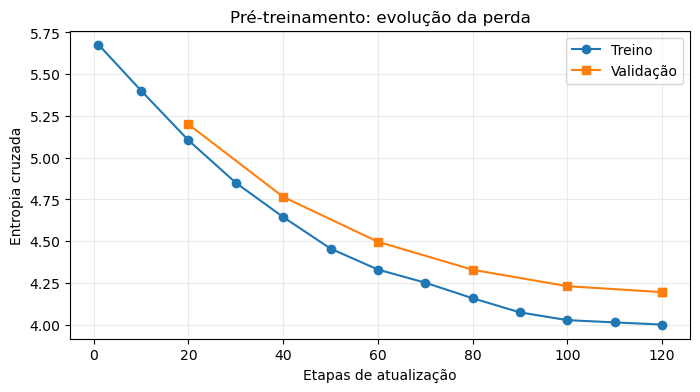

In [12]:
historico = pd.DataFrame(trainer.state.log_history)
fig, ax = plt.subplots(figsize=(8, 4))
if "loss" in historico:
    t = historico.dropna(subset=["loss"])
    ax.plot(t["step"], t["loss"], marker="o", label="Treino")
if "eval_loss" in historico:
    v = historico.dropna(subset=["eval_loss"])
    ax.plot(v["step"], v["eval_loss"], marker="s", label="Validação")
ax.set(xlabel="Etapas de atualização", ylabel="Entropia cruzada", title="Pré-treinamento: evolução da perda")
ax.grid(alpha=.25)
ax.legend()
plt.show()

## 7. O que mudou nas previsões?

Compare os tokens mais prováveis antes e depois. Atenção: um token BPE pode ser **parte de uma palavra**, e sua representação interna pode conter marcas de bytes ou espaços.

In [13]:
previsoes_depois = {p: proximo_token(model, tokenizer, p, 8) for p in PROMPTS}
for p in PROMPTS:
    print("\nPROMPT:", repr(p))
    print("Antes:")
    display(previsoes_antes[p][["texto decodificado", "probabilidade"]])
    print("Depois:")
    display(previsoes_depois[p][["texto decodificado", "probabilidade"]])


PROMPT: 'O gato'
Antes:


,texto decodificado,probabilidade
0,'to',0.006094
1,'�',0.004430
2,'�',0.003930
3,'�',0.003907
4,' u',0.003865
5,' ex',0.003639
6,'8',0.003635
7,"""'""",0.003630


Depois:


,texto decodificado,probabilidade
0,'.',0.029163
1,' ',0.022662
2,'o',0.021140
3,'i',0.016675
4,'to',0.016053
5,' a',0.015427
6,' na',0.015103
7,'or',0.014759



PROMPT: 'A professora'
Antes:


,texto decodificado,probabilidade
0,'ora',0.005021
1,' exp',0.003889
2,'_',0.003827
3,'\x10',0.003794
4,'nte',0.003723
5,' durante',0.003715
6,'mos',0.003708
7,'B',0.003704


... (6 outputs left out)


PROMPT: 'A chuva'
Antes:


,texto decodificado,probabilidade
0,'va',0.004924
1,'ç',0.004075
2,'3',0.003661
3,' pe',0.003619
4,'�',0.003614
5,'8',0.003551
6,'�',0.003512
7,'I',0.003510


Depois:


,texto decodificado,probabilidade
0,'o',0.023258
1,' ',0.022239
2,'or',0.017433
3,' a',0.014950
4,'ma',0.014614
5,' p',0.014534
6,' na',0.013384
7,'li',0.013352


### Probabilidade de uma continuação completa

Como palavras podem ser representadas por **vários tokens**, não basta consultar a probabilidade de um único ID. A função abaixo calcula a soma dos logaritmos das probabilidades dos tokens de uma continuação candidata, condicionando cada previsão aos tokens anteriores. Para fins didáticos, incluímos um espaço inicial na continuação quando necessário.

In [14]:
def prob_continuacao(model, tokenizer, prefixo, continuacao):
    model.eval()
    ids_pref = [tokenizer.bos_token_id] + tokenizer(prefixo, add_special_tokens=False)["input_ids"]
    ids_cont = tokenizer(continuacao, add_special_tokens=False)["input_ids"]
    ids = ids_pref + ids_cont
    inp = torch.tensor([ids], device=next(model.parameters()).device)
    with torch.no_grad():
        logits = model(input_ids=inp).logits[0]
        log_probs = logits.log_softmax(-1)
    indices_de_contexto = range(len(ids_pref)-1, len(ids)-1)
    soma = sum(float(log_probs[i, ids[i+1]]) for i in indices_de_contexto)
    return soma

candidatas = [" dorme no sofá.", " come uma maçã.", " explica matemática."]
tabela_candidatas = pd.DataFrame([
    {"continuação": c, "log P(continuação | contexto)": prob_continuacao(model, tokenizer, "O gato", c)}
    for c in candidatas
])
display(tabela_candidatas.sort_values("log P(continuação | contexto)", ascending=False))
print("Comparar log-probabilidades de sequências de comprimentos distintos exige cuidado:",
      "sequências maiores acumulam mais termos.")

,continuação,log P(continuação | contexto)
1,come uma maçã.,-36.461080
0,dorme no sofá.,-39.877241
2,explica matemática.,-42.567939


Comparar log-probabilidades de sequências de comprimentos distintos exige cuidado: sequências maiores acumulam mais termos.


### Gerar texto

A escolha gulosa seleciona o próximo token de maior probabilidade em cada etapa; não garante a sequência globalmente mais provável. A amostragem pode aumentar diversidade, mas pode gerar sequências incoerentes. Experimentaremos ambas.

In [15]:
for prompt in PROMPTS:
    print("\nPrompt:", repr(prompt))
    print("Antes (gulosa): ", geracoes_antes[prompt])
    print("Depois (gulosa):", gerar(model, tokenizer, prompt, amostrar=False))
    print("Depois (amostra):", gerar(model, tokenizer, prompt, amostrar=True))


Prompt: 'O gato'
Antes (gulosa):  O gatototototototototototototototototo
Depois (gulosa): O gato.
Depois (amostra): O gatooro.

Prompt: 'A professora'
Antes (gulosa):  A professoraoraoraoraoraoraoraoraoraoraoraoraoraoraora exp exp
Depois (gulosa): A professora na umannnnnnn.
Depois (amostra): A professoralora.

Prompt: 'O modelo'
Antes (gulosa):  O modelooooooooooooooooo
Depois (gulosa): O modelo.
Depois (amostra): O modelooroo. p p pzala manhã na uman u.

Prompt: 'A chuva'
Antes (gulosa):  A chuvavavava
Depois (gulosa): A chuvao.
Depois (amostra): A chuvalb


## 8. Salvar o modelo e tokenizador

Esses artefatos são o ponto de partida para o **Companion 02 — SFT**. O pré-treinamento produziu uma distribuição de probabilidades sobre continuações; o SFT ensinará o modelo a tratar determinados textos como instruções e respostas desejáveis.

In [16]:
pasta_modelo = Path("artefatos_pretraining/modelo")
pasta_tokenizador = Path("artefatos_pretraining/tokenizador")
pasta_modelo.mkdir(parents=True, exist_ok=True)
pasta_tokenizador.mkdir(parents=True, exist_ok=True)
model.save_pretrained(pasta_modelo, safe_serialization=True)
tokenizer.save_pretrained(pasta_tokenizador)
print("Modelo:", pasta_modelo.resolve())
print("Tokenizador:", pasta_tokenizador.resolve())
print("Para reutilizar no Companion 02:")
print('tokenizer = PreTrainedTokenizerFast.from_pretrained("artefatos_pretraining/tokenizador")')
print('model = GPT2LMHeadModel.from_pretrained("artefatos_pretraining/modelo")')

Modelo: /Users/ebezerra/ailab/gcc1734/notebooks/artefatos_pretraining/modelo
Tokenizador: /Users/ebezerra/ailab/gcc1734/notebooks/artefatos_pretraining/tokenizador
Para reutilizar no Companion 02:
tokenizer = PreTrainedTokenizerFast.from_pretrained("artefatos_pretraining/tokenizador")
model = GPT2LMHeadModel.from_pretrained("artefatos_pretraining/modelo")


## 9. Atividades para os alunos

1. **Vocabulário:** altere `vocab_size` do BPE (por exemplo, 300 e 512). Como mudam a quantidade de tokens por frase e o tamanho da matriz de embeddings?
2. **Predição:** selecione uma frase e mostre a correspondência entre seus IDs e os pares contexto/alvo. Por que há uma previsão a menos que o total de IDs quando nenhuma informação anterior à sequência é fornecida?
3. **Perda:** compare a loss do modelo com a entropia cruzada calculada manualmente. O que acontece se uma predição atribui probabilidade próxima de zero ao token observado?
4. **Generalização:** compare exemplos de treino e validação. Uma loss baixa de validação demonstra que o modelo entende português fora do corpus sintético? Por quê?
5. **Ablação:** repita o treinamento com menos dados ou menos etapas. Compare a loss e a geração para o mesmo prompt.
6. **Próxima etapa:** experimente apresentar `Explique o que é aprendizado por reforço em duas frases.`. O modelo consegue seguir a instrução? O que ainda falta no objetivo de pré-treinamento?

**Discussão:** o tokenizador foi treinado somente no split de treinamento, evitando usar frases reservadas para avaliação na construção do vocabulário. Esse cuidado torna o experimento mais claro, mas não é a única escolha possível em aplicações reais.

### Referências da API

- [Hugging Face — Causal language modeling](https://huggingface.co/docs/transformers/tasks/language_modeling)
- [Hugging Face — Training with Trainer](https://huggingface.co/docs/transformers/main/training)
- [Hugging Face — Tokenizers](https://huggingface.co/docs/tokenizers/index)